# Complex Characterization

This directory holds the complexes that models disagreed on (and those they agreed on). By pulling the appropriate files from the DIPPlus set we can see the structures themselves and characterize them somehow.

I'm not quite sure the best way to characterize them yet, but firstly I just want to write out the functions to actually get everything. Right away I want a way to read in a list of complexes from file

In [1]:
import joblib
import dill
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
import random
import math

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../../src_code')))

from data_utils import get_complex_dill, filter_keys

import matplotlib as mpl
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}
plt.rcParams['font.weight'] = 'bold'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = 'freesans'
# mpl.rcParams['legend.fontsize'] = 18
# mpl.rcParams['legend.title_fontsize'] = 22
# mpl.rcParams['axes.labelsize'] = 22
# mpl.rcParams['axes.titlesize'] = 24
# mpl.rcParams['xtick.labelsize'] = 18
# mpl.rcParams['ytick.labelsize'] = 18

/home/desktop7/Softwares/miniforge3/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
complex_info = pd.read_csv('/media/desktop7/b04495a5-e11b-418b-a62f-8738b9349519/protein_dataset_tests/main/data/dipsplus_raw/complex_info_with_interface_areas.csv')
complex_info = complex_info[complex_info['seq1_len'] <= 650]
complex_info = complex_info[complex_info['seq2_len'] <= 650]

## Convert to nm2
complex_info['interface_area'] = complex_info['interface_area'] / 100  # Convert from Å² to nm²



def load_complex_list(path):
    with open(path, 'r') as f:
        f.readline()
        return [line.strip().split(' ') for line in f] #remove newline and give pairs of complex and hit count

def load_similarity_data(path):
    df = pd.read_csv(path, skiprows=1, delimiter=' ', names=['complex_path', 'SAS', 'CKA', 'Frob', 'Nuclear'])
    return df[['complex_path', 'CKA']]

print(load_similarity_data('similarities/aminobert-esm2-interfacearea20-targeted-trial_0-val-similarities.dat'))

              complex_path       CKA
0     qg/3qgk.pdb1_14.dill  0.017136
1      cf/3cf0.pdb1_2.dill  0.771118
2      gb/2gbl.pdb1_0.dill  0.062097
3      ws/3wse.pdb1_5.dill  0.924911
4      iy/1iyl.pdb5_0.dill  0.751806
...                    ...       ...
2868   kb/1kbn.pdb1_0.dill  0.919414
2869   fz/1fzw.pdb1_5.dill  0.843387
2870   f7/1f73.pdb1_0.dill  0.796769
2871   au/1aux.pdb1_0.dill  0.302842
2872   p9/4p9c.pdb2_0.dill  0.846054

[2873 rows x 2 columns]


In [3]:
complex_info

,complex_path,seq1_len,seq2_len,interface_res_count,interface_area
0,fu/4fur.pdb2_1.dill,100,100,39,5.396040
1,fu/2fu4.pdb1_0.dill,81,81,56,5.088859
2,fu/1fui.pdb1_2.dill,591,591,206,19.301251
3,fu/2fur.pdb1_0.dill,188,185,274,26.347882
4,fu/2fu4.pdb3_0.dill,81,81,56,5.088859
...,...,...,...,...,...
39144,k6/3k6c.pdb1_8.dill,89,90,194,22.199867
39145,k6/3k6c.pdb1_11.dill,90,89,29,3.351621
39146,k6/3k6c.pdb1_14.dill,89,89,29,3.214382
39147,k6/3k6c.pdb1_5.dill,88,89,114,12.052151


# full DIPS-Plus Interface Areas

I think the modality behavior of the similar and dissimilar complexes' respective interfaace area KDEs is in part due to that of the complete dataset.

In [4]:
complex_info.describe()

,seq1_len,seq2_len,interface_res_count,interface_area
count,38243.000000,38243.000000,38243.000000,38243.000000
mean,250.949089,238.414350,132.072510,12.859392
std,124.467518,123.139023,101.569513,9.193622
min,14.000000,7.000000,1.000000,0.010825
25%,155.000000,149.000000,60.000000,6.339330
50%,233.000000,218.000000,108.000000,10.678503
75%,325.000000,309.000000,169.000000,16.182656
max,650.000000,650.000000,1027.000000,93.891262


findfont: Failed to find font weight bold, now using 600.


Text(0.5, 1.0, 'Complete DIPS-Plus Interface Area Distribution')

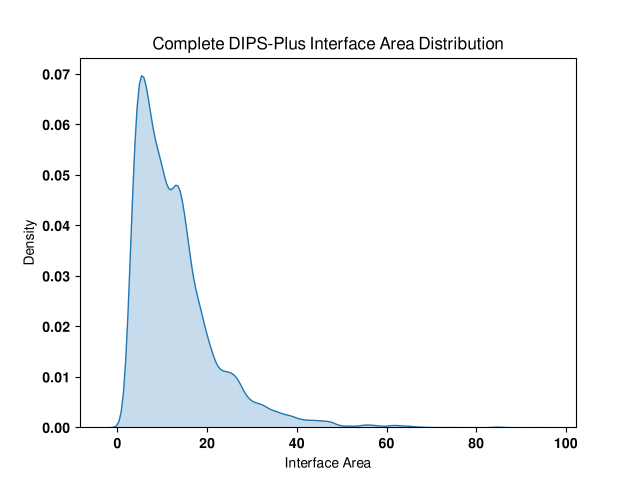

In [5]:
sns.kdeplot(data=complex_info, x='interface_area', fill=True)
plt.xlabel('Interface Area')
plt.title("Complete DIPS-Plus Interface Area Distribution")

From the output of the cell below, the two modes on the left-hand side are at 545 and 1306.

In [6]:
from scipy.signal import find_peaks
from scipy.stats import gaussian_kde

def find_kde_peaks(data, bandwidth='scott', num_points=1000):
    kde = gaussian_kde(data, bw_method=bandwidth)
    x = np.linspace(data.min()-1, data.max()+1, num_points)
    density = kde(x)
    peaks, _ = find_peaks(density)
    peak_x = x[peaks]
    peak_y = density[peaks]
    return peak_x, peak_y


data = complex_info['interface_area'].values

peak_x, peak_y = find_kde_peaks(data)

print("Peak x-values:", peak_x)
print("Peak y-values:", peak_y)


Peak x-values: [ 5.44124493 13.02338158 55.63690908 61.77939953 74.25633326 84.71776231
 93.93149799]
Peak y-values: [6.98128530e-02 4.80722244e-02 5.34552388e-04 4.44077662e-04
 2.73608308e-05 1.01761780e-04 9.35618309e-06]


# Specific Trials

Different trials have different interface area ranges. The way we did augmentation prioritized complexes that were repeatedly failed. It may be at least partially useful to first do this notebook in terms of specific trials, before moving onto the aggregated results used. Then we can describe 1) what made a particular ablation struggle and 2) what're the difficulties of the model?

These cells pull a specific trial, get their distributions, and sample some similar and dissimilar

In [7]:
PERCENT_ABLATE=80
TRIAL=2
ABLATE_TYPE='targeted'

# load in one specific trial
val_sims = load_similarity_data(f'similarities/aminobert-esm2-interfacearea{PERCENT_ABLATE}-{ABLATE_TYPE}-trial_{TRIAL}-val-similarities.dat')
train_sims = load_similarity_data(f'similarities/aminobert-esm2-interfacearea{PERCENT_ABLATE}-{ABLATE_TYPE}-trial_{TRIAL}-train-similarities.dat')
holdout_sims = load_similarity_data(f'similarities/aminobert-esm2-interfacearea{PERCENT_ABLATE}-{ABLATE_TYPE}-trial_{TRIAL}-holdout-similarities.dat')

#remove holdouts from the validation set
val_sims = val_sims[~val_sims['complex_path'].isin(holdout_sims['complex_path'])]
display(val_sims)

,complex_path,CKA
0,qi/4qii.pdb1_11.dill,0.884471
1,hc/1hcq.pdb1_0.dill,0.409712
2,qw/4qws.pdb1_86.dill,0.948028
3,kp/4kpc.pdb1_0.dill,0.917004
4,c5/3c5y.pdb1_0.dill,0.423905
...,...,...
6634,a8/2a8c.pdb1_0.dill,0.583609
6637,y8/4y8q.pdb1_78.dill,0.967108
6638,o8/4o8r.pdb4_0.dill,0.970605
6639,p9/4p9c.pdb2_0.dill,0.863527


In [8]:
val_info = pd.merge(val_sims, complex_info, on='complex_path', how='inner').sort_values(by='CKA', ascending=True)
#label top 20%cka, bottom 20%cka, and rest. top is "similar", bottom is "dissimilar", rest is "neutral"
val_info['Similarity Group'] = pd.qcut(val_info['CKA'], q=[0, 0.2, 0.8, 1.0], labels=['dissimilar', 'neutral', 'similar'])
val_info

,complex_path,CKA,seq1_len,seq2_len,interface_res_count,interface_area,Similarity Group
4010,ya/4ya0.pdb1_21.dill,0.001357,240,195,27,4.085163,dissimilar
1417,y7/4y7y.pdb1_17.dill,0.001357,240,195,28,4.116848,dissimilar
4103,o3/2o3i.pdb2_0.dill,0.001542,366,365,66,7.220951,dissimilar
1595,qa/1qaj.pdb1_0.dill,0.002692,259,257,76,7.243935,dissimilar
1078,z4/1z40.pdb1_0.dill,0.003024,311,306,41,4.655749,dissimilar
...,...,...,...,...,...,...,...
2174,qi/2qi4.pdb1_0.dill,0.992101,99,99,183,18.294795,similar
437,to/3tof.pdb1_0.dill,0.992120,99,99,184,18.237973,similar
4547,pw/3pwm.pdb1_0.dill,0.992245,99,99,182,18.375642,similar
1719,fx/2fxe.pdb1_0.dill,0.992258,99,99,182,17.901199,similar


<Axes: xlabel='interface_area', ylabel='Density'>

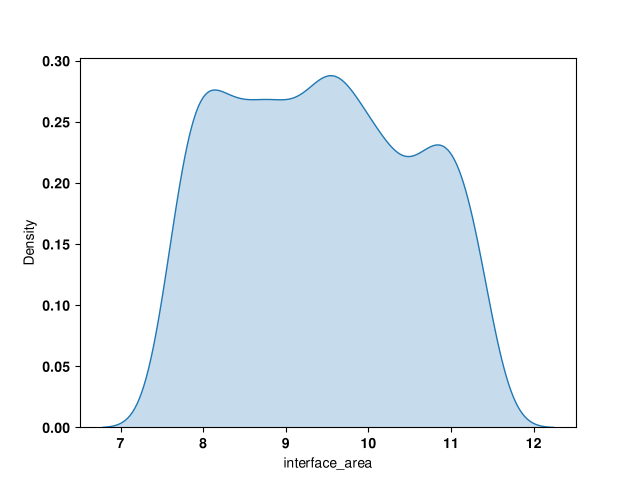

In [9]:
# See the dist of the complete set
sns.kdeplot(data=val_info, x='interface_area', fill=True)

In [10]:
#see the peaks in the full set KDE
peak_x, peak_y = find_kde_peaks(val_info['interface_area'].values)
print("Peak x-values:", peak_x)
print("Peak y-values:", peak_y)

Peak x-values: [ 8.13557097  8.75993747  9.53745046 10.83330546]
Peak y-values: [0.27630624 0.26853775 0.28801093 0.23136346]


Text(0, 0.5, 'Density')

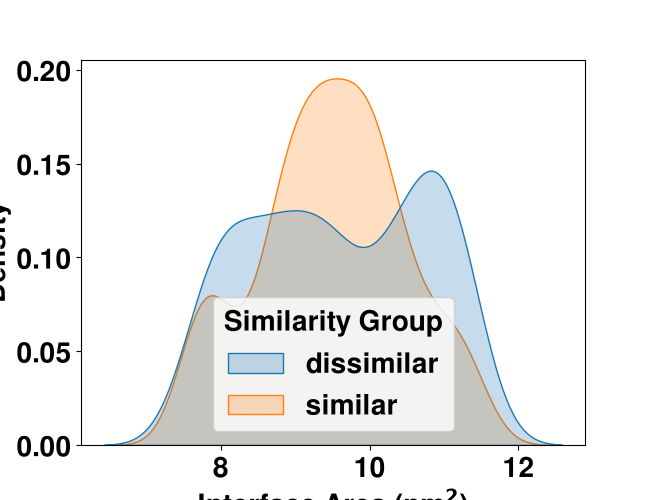

In [ ]:
val_info = val_info[val_info['Similarity Group'] != 'neutral']
val_info['Similarity Group'] = val_info['Similarity Group'].cat.remove_unused_categories()
plt.figure(figsize=(6.5,5))
sns.kdeplot(data=val_info, x='interface_area', hue='Similarity Group', fill=True)
plt.xlabel("Interface Area (nm$^2$)",fontweight='bold', fontsize=20)
plt.ylabel('Density', fontweight='bold', fontsize=20)

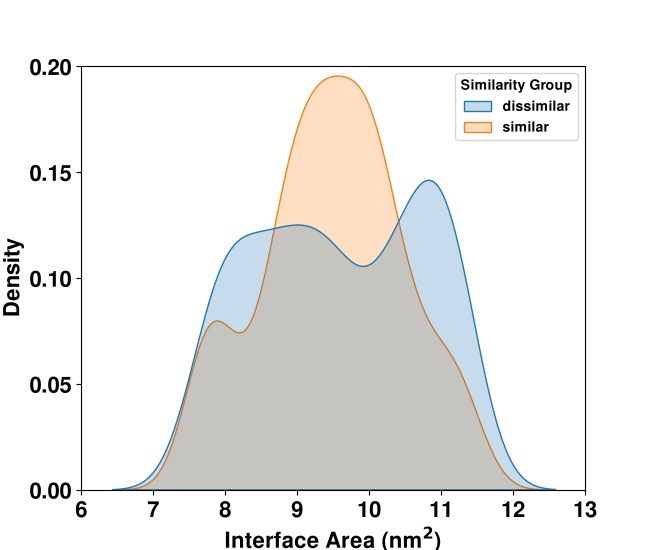

In [16]:
# REMOVE THE UNUSED CATEGORY
val_info = val_info[val_info['Similarity Group'] != 'neutral']
val_info['Similarity Group'] = val_info['Similarity Group'].cat.remove_unused_categories()
plt.figure(figsize=(6.5,5.5))
sns.kdeplot(data=val_info, x='interface_area', hue='Similarity Group', fill=True)
plt.xlabel("Interface Area (nm$^2$)",fontweight='bold', fontsize=16)
plt.ylabel('Density', fontweight='bold', fontsize=16)
plt.ylim(0, 0.2)
plt.yticks(np.linspace(0, 0.2, 5), fontweight='bold', fontsize=16)
plt.xlim(6, 13)
plt.xticks(fontweight='bold', fontsize=16)
# plt.title("Extensive Targeted Ablation (Trial 2)", fontweight='bold')

plt.savefig("/media/desktop7/b04495a5-e11b-418b-a62f-8738b9349519/protein_dataset_tests/main/figs/extensive_targeted_ablation_trial_2.svg", dpi=300)

/tmp/ipykernel_780250/980804403.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[0].set_xticklabels(np.linspace(0, 40, 5), fontweight='bold')
/tmp/ipykernel_780250/980804403.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[1].set_xticklabels(np.linspace(0, 80, 5), fontweight='bold')
/tmp/ipykernel_780250/980804403.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(np.linspace(0, 0.07, 8), fontweight='bold')
/tmp/ipykernel_780250/980804403.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be m

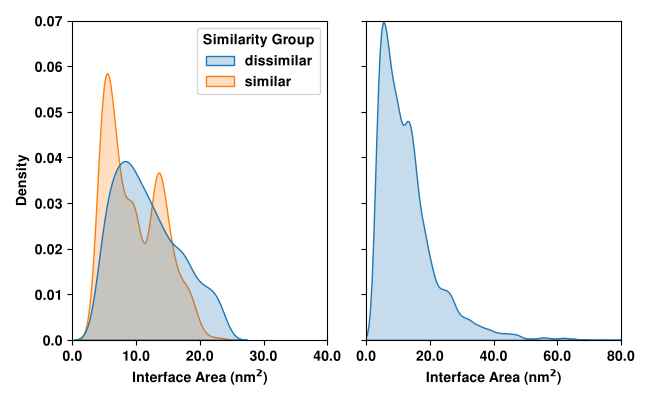

In [28]:

val_info = val_info[val_info['Similarity Group'] != 'neutral']
val_info['Similarity Group'] = val_info['Similarity Group'].cat.remove_unused_categories()

fig, axs = plt.subplots(1, 2, figsize=(6.5, 4), sharey=True)

sns.kdeplot(data=complex_info, x='interface_area', fill=True, ax=axs[1])
sns.kdeplot(data=val_info, x='interface_area', hue='Similarity Group', fill=True, ax = axs[0])

axs[0].set_xlabel("Interface Area (nm$^2$)", fontweight='bold')
# axs[0].set_title("Limited Targeted Ablation\n(Trial 3)", fontweight='bold', fontsize='medium')
axs[0].set_xlim(0,40)
axs[0].set_xticklabels(np.linspace(0, 40, 5), fontweight='bold')
axs[1].set_xlabel("Interface Area (nm$^2$)", fontweight='bold')
# axs[1].set_title("Complete DIPS-Plus\nInterface Area Distribution", fontweight='bold', fontsize='medium')
axs[1].set_xlim(0, 80)
axs[1].set_xticklabels(np.linspace(0, 80, 5), fontweight='bold')

for ax in axs:
    ax.set_ylabel("Density", fontweight='bold', fontsize='medium')
    ax.set_ylim(0, 0.07)
    ax.set_yticklabels(np.linspace(0, 0.07, 8), fontweight='bold')
fig.tight_layout()
plt.savefig("/media/desktop7/b04495a5-e11b-418b-a62f-8738b9349519/protein_dataset_tests/main/figs/limited_targeted_ablation_trial_3_v1.svg", dpi=300)

findfont: Failed to find font weight bold, now using 600.
findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 600.


<Figure size 640x480 with 0 Axes>

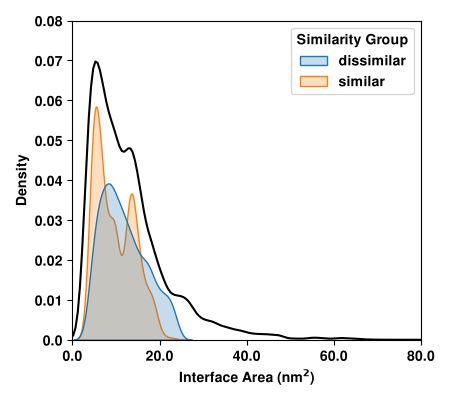

In [9]:
#as above but the two share a plot
val_info = val_info[val_info['Similarity Group'] != 'neutral']
val_info['Similarity Group'] = val_info['Similarity Group'].cat.remove_unused_categories()

plt.clf()
# Removed sharey=True as it is redundant for a 1x1 grid
fig, axs = plt.subplots(1, 1, figsize=(4.5, 4))

sns.kdeplot(data=complex_info, x='interface_area', fill=False, ax=axs, color='black')
sns.kdeplot(data=val_info, x='interface_area', hue='Similarity Group', fill=True, ax=axs)

axs.set_xlabel("Interface Area (nm$^2$)", fontweight='bold')

# 1. Set the limits first
axs.set_xlim(0, 80)

# 2. Lock in the exact tick locations
x_ticks = np.linspace(0, 80, 5)
axs.set_xticks(x_ticks)

# 3. Apply the bold formatting to those specific locations
axs.set_xticklabels(x_ticks, fontweight='bold')

axs.set_ylabel("Density", fontweight='bold', fontsize='medium')

# Repeat the Limit -> Location -> Label order for the y-axis
axs.set_ylim(0, 0.08)

y_ticks = np.linspace(0, 0.08, 9)
axs.set_yticks(y_ticks)

# Use np.round to prevent floating point artifacts (e.g., 0.010000000000000002) in labels
axs.set_yticklabels(np.round(y_ticks, 2), fontweight='bold')

fig.tight_layout()
plt.savefig("/media/desktop7/b04495a5-e11b-418b-a62f-8738b9349519/protein_dataset_tests/main/figs/limited_targeted_ablation_trial_3_v2.svg", dpi=300)

In [12]:
for group, group_df in val_info.groupby('Similarity Group'):
    print(f"Group: {group}")
    group_data = group_df['interface_area']

    px, py = find_kde_peaks(group_data.values)
    print("Peak x-values:", px)
    print("Peak y-values:", py)

Group: dissimilar
Peak x-values: [825.37994877]
Peak y-values: [0.00078413]
Group: similar
Peak x-values: [ 543.1620962  1354.33982332]
Peak y-values: [0.0011694  0.00073399]


/tmp/ipykernel_3577517/3128501242.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group, group_df in val_info.groupby('Similarity Group'):


## Sampling Complexes

In [13]:
#select three dissimilar complexes, three similar ones
dissimilar_complexes = val_info[val_info['Similarity Group'] == 'dissimilar']
similar_complexes = val_info[val_info['Similarity Group'] == 'similar']

In [14]:
dissimilar_complexes[dissimilar_complexes['interface_area'] > 1000]

,complex_path,CKA,seq1_len,seq2_len,interface_res_count,interface_area,Similarity Group
2921,a9/5a9d.pdb1_0.dill,0.003280,189,189,170,1688.468977,dissimilar
1885,fp/1fp3.pdb1_0.dill,0.004331,402,402,98,1014.598528,dissimilar
2848,y4/2y4o.pdb1_0.dill,0.004473,433,432,209,1949.033860,dissimilar
2480,eq/4eql.pdb3_0.dill,0.006305,494,479,120,1152.462358,dissimilar
1730,a1/5a11.pdb1_0.dill,0.006365,345,345,97,1082.475301,dissimilar
...,...,...,...,...,...,...,...
4578,au/3au9.pdb1_0.dill,0.616730,410,410,226,1936.973819,dissimilar
3324,ix/4ixs.pdb1_0.dill,0.616987,360,371,142,1423.379014,dissimilar
4739,r1/4r1o.pdb1_4.dill,0.617619,495,496,244,2268.625341,dissimilar
3135,vx/2vxx.pdb1_0.dill,0.619811,172,173,193,1801.061861,dissimilar


In [15]:
similar_complexes[(similar_complexes['interface_area'] < 700) & (similar_complexes['complex_path'].str.contains('1_0'))].sort_values(by='interface_area')

,complex_path,CKA,seq1_len,seq2_len,interface_res_count,interface_area,Similarity Group
4404,fb/3fbb.pdb1_0.dill,0.963383,133,132,52,479.016545,similar
1668,b8/2b8q.pdb1_0.dill,0.950434,133,132,54,485.375097,similar
1863,mn/1mn7.pdb1_0.dill,0.932444,150,150,78,628.113906,similar
4211,qv/4qvd.pdb1_0.dill,0.928522,60,60,61,639.981059,similar


In [16]:
display(dissimilar_complexes)
display(similar_complexes)

,complex_path,CKA,seq1_len,seq2_len,interface_res_count,interface_area,Similarity Group
4010,ya/4ya0.pdb1_21.dill,0.001357,240,195,27,408.516335,dissimilar
1417,y7/4y7y.pdb1_17.dill,0.001357,240,195,28,411.684757,dissimilar
4103,o3/2o3i.pdb2_0.dill,0.001542,366,365,66,722.095147,dissimilar
1595,qa/1qaj.pdb1_0.dill,0.002692,259,257,76,724.393486,dissimilar
1078,z4/1z40.pdb1_0.dill,0.003024,311,306,41,465.574896,dissimilar
...,...,...,...,...,...,...,...
1553,kx/3kxy.pdb1_2.dill,0.618935,130,37,70,767.900755,dissimilar
2700,tm/4tma.pdb1_0.dill,0.619010,505,374,65,691.422961,dissimilar
3135,vx/2vxx.pdb1_0.dill,0.619811,172,173,193,1801.061861,dissimilar
1398,ce/2ce9.pdb2_0.dill,0.619884,337,332,132,1102.928144,dissimilar


,complex_path,CKA,seq1_len,seq2_len,interface_res_count,interface_area,Similarity Group
3224,s5/1s57.pdb1_10.dill,0.920954,153,153,83,854.577209,similar
735,ix/4ixk.pdb1_1.dill,0.921221,155,157,47,427.492365,similar
2916,du/1dub.pdb1_8.dill,0.921293,259,259,38,443.528631,similar
2855,ej/2ej3.pdb1_2.dill,0.921339,304,294,68,803.110199,similar
2112,a3/4a34.pdb1_12.dill,0.921384,140,142,71,970.595528,similar
...,...,...,...,...,...,...,...
2174,qi/2qi4.pdb1_0.dill,0.992101,99,99,183,1829.479521,similar
437,to/3tof.pdb1_0.dill,0.992120,99,99,184,1823.797303,similar
4547,pw/3pwm.pdb1_0.dill,0.992245,99,99,182,1837.564202,similar
1719,fx/2fxe.pdb1_0.dill,0.992258,99,99,182,1790.119926,similar


In [17]:
val_info.groupby('cka_label').describe()['interface_area']

KeyError: 'cka_label'

# Viewing Multiple/All Trials

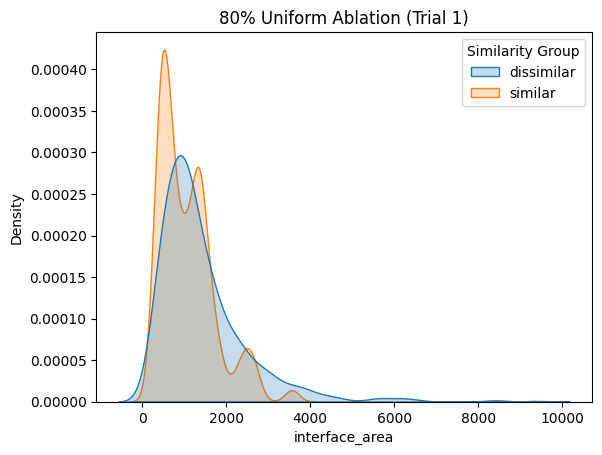

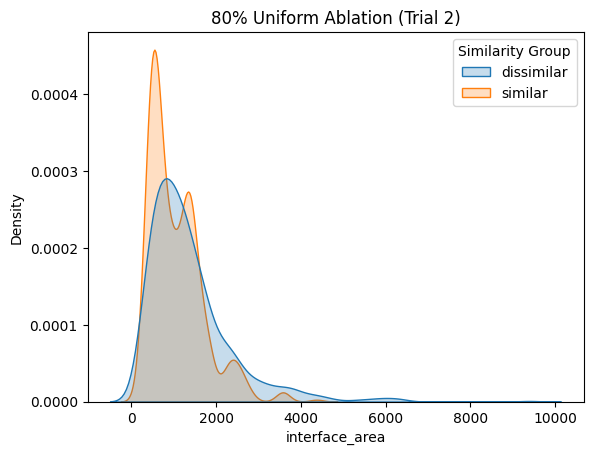

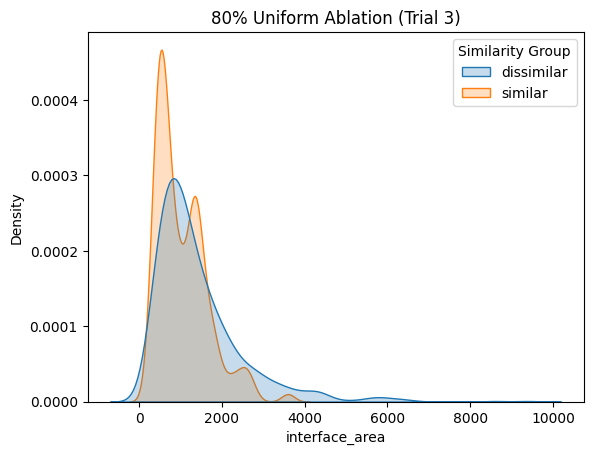

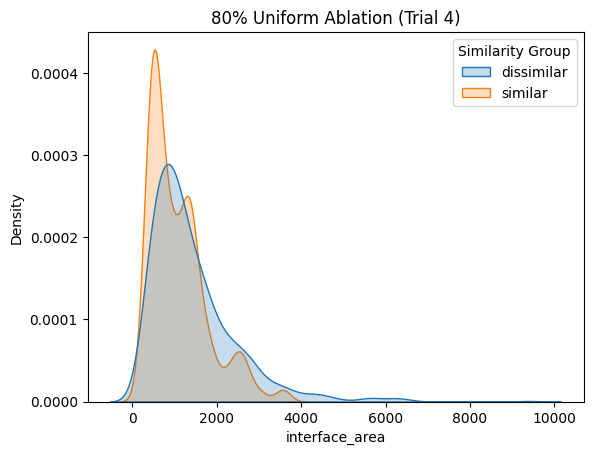

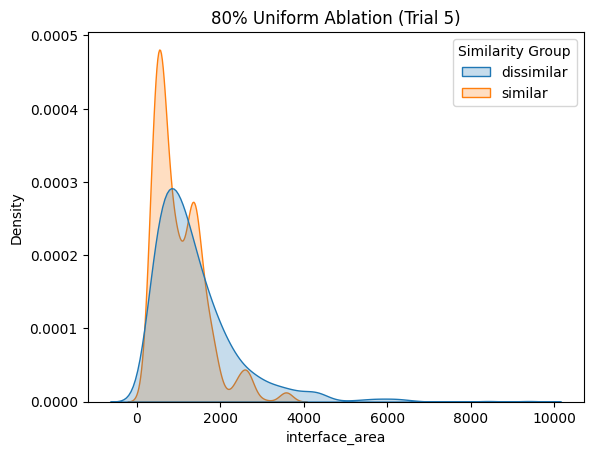

In [21]:
#do it for all trials.
for trial in range(5):
    val_sims = load_similarity_data(f'similarities/aminobert-esm2-interfacearea80-uniform-trial_{trial}-val-similarities.dat')
    train_sims = load_similarity_data(f'similarities/aminobert-esm2-interfacearea80-uniform-trial_{trial}-train-similarities.dat')
    holdout_sims = load_similarity_data(f'similarities/aminobert-esm2-interfacearea80-uniform-trial_{trial}-holdout-similarities.dat')

    #remove holdouts from the validation set
    val_sims = val_sims[~val_sims['complex_path'].isin(holdout_sims['complex_path'])]

    val_info = pd.merge(val_sims, complex_info, on='complex_path', how='inner').sort_values(by='CKA', ascending=True)
    #label top 20%cka, bottom 20%cka, and rest. top is "similar", bottom is "dissimilar", rest is "neutral"
    val_info['Similarity Group'] = pd.qcut(val_info['CKA'], q=[0, 0.2, 0.8, 1.0], labels=['dissimilar', 'neutral', 'similar'])
    # Filter out 'neutral'
    val_info = val_info[val_info['Similarity Group'] != 'neutral']

    # REMOVE THE UNUSED CATEGORY
    val_info['Similarity Group'] = val_info['Similarity Group'].cat.remove_unused_categories()
    sns.kdeplot(data=val_info, x='interface_area', hue='Similarity Group', fill=True)
    #sns.kdeplot(data=val_info, x='CKA', y='interface_area', fill=True)
    plt.title(f'80% Uniform Ablation (Trial {trial+1})')

    plt.show()

    

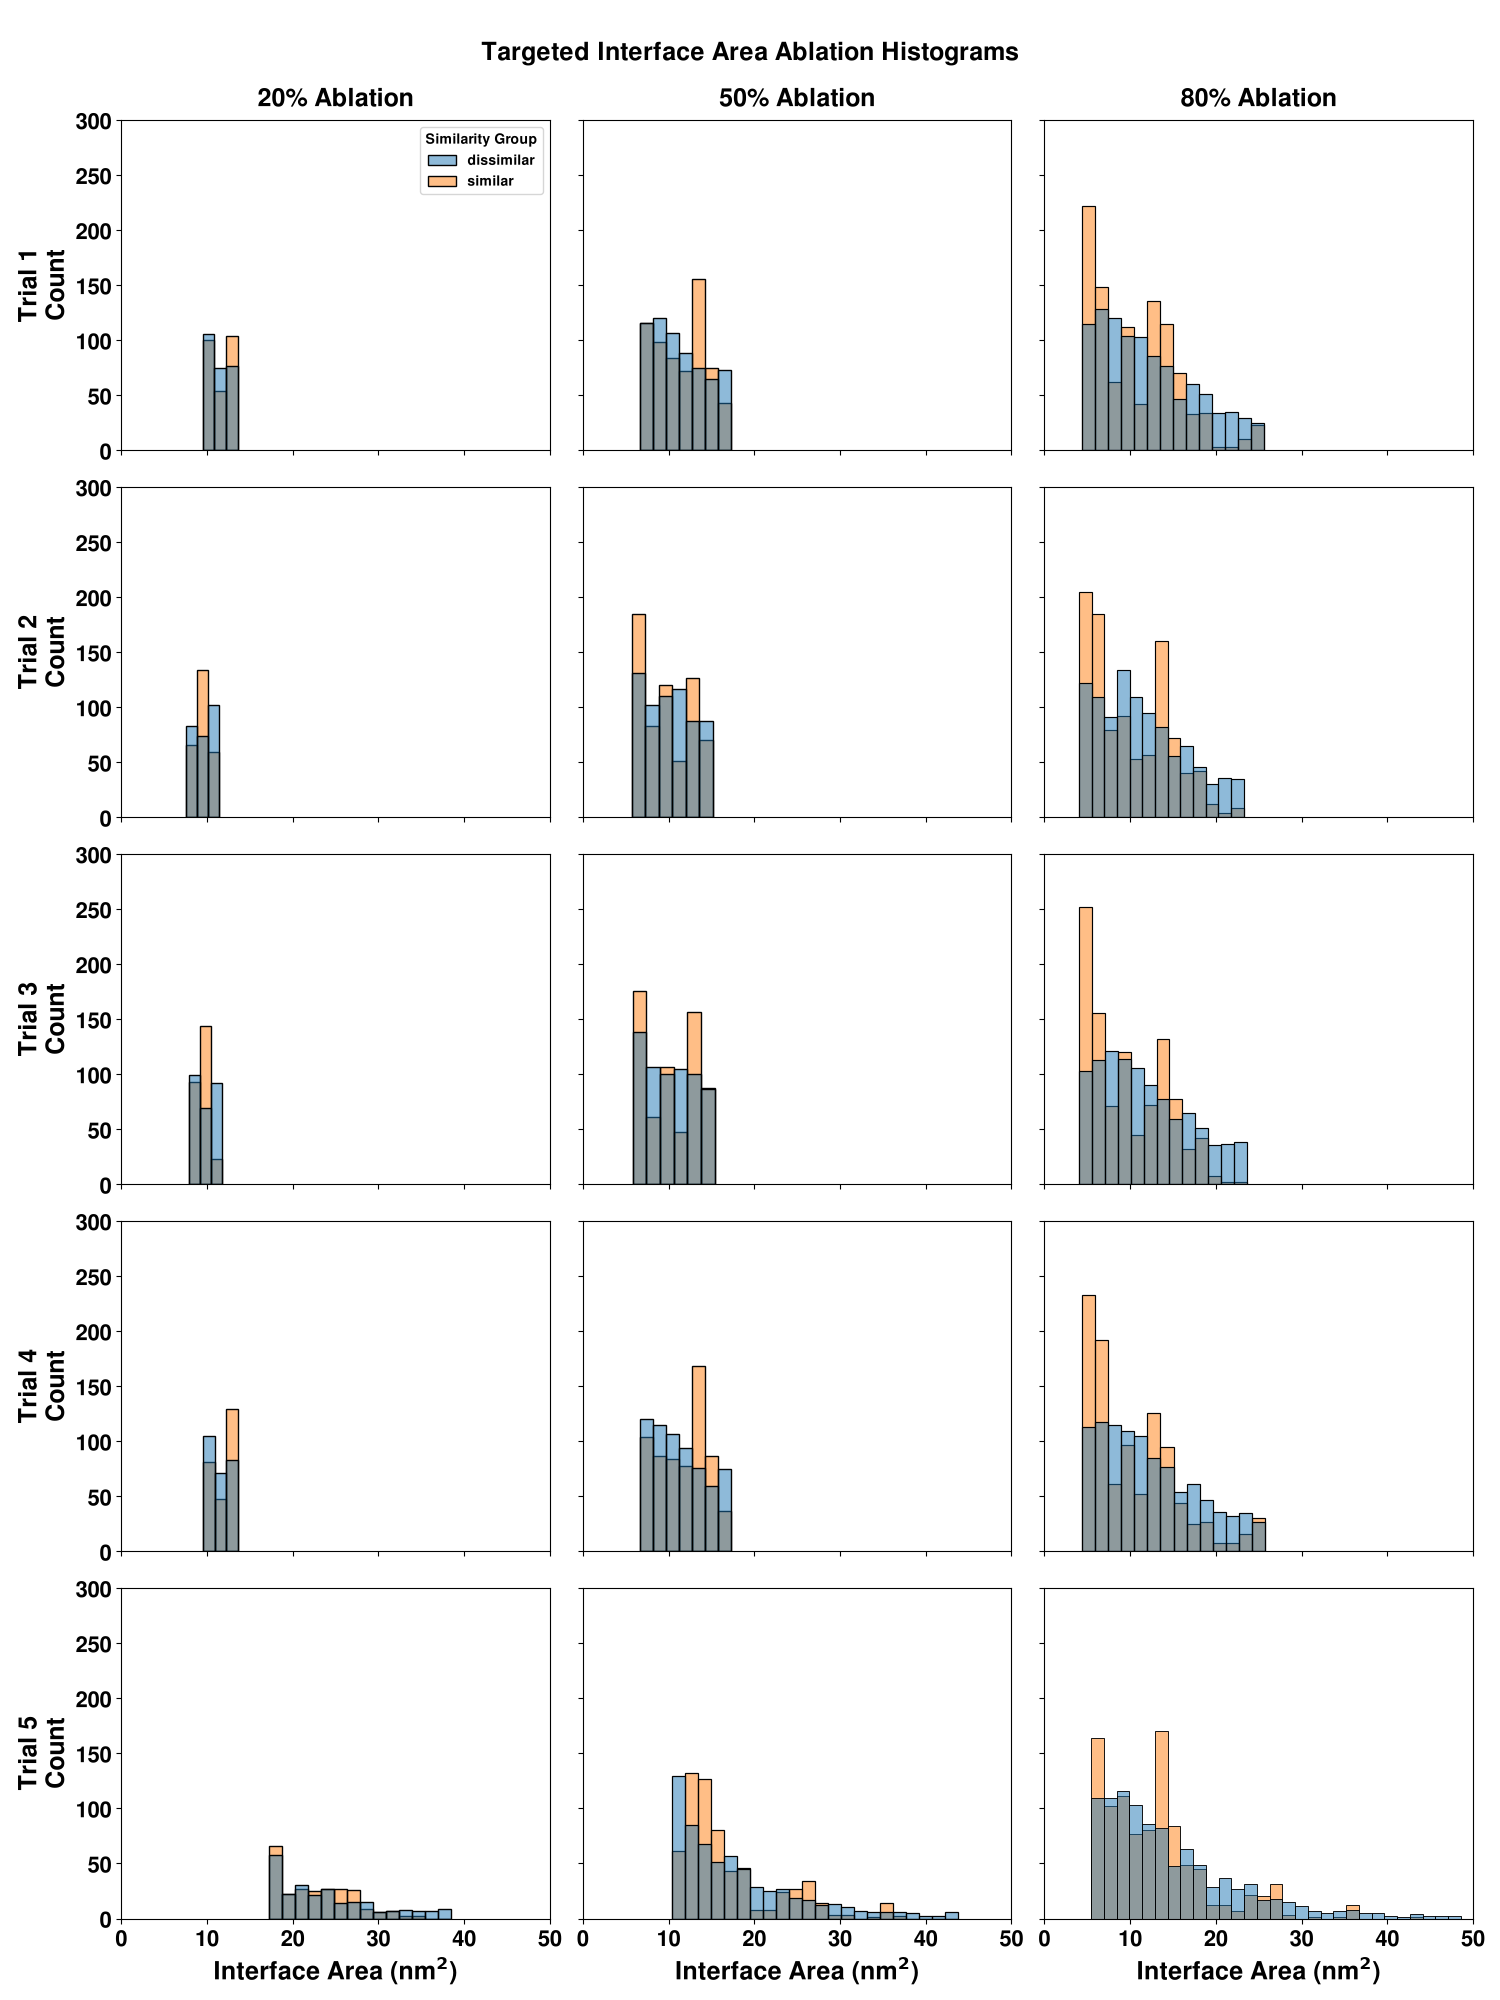

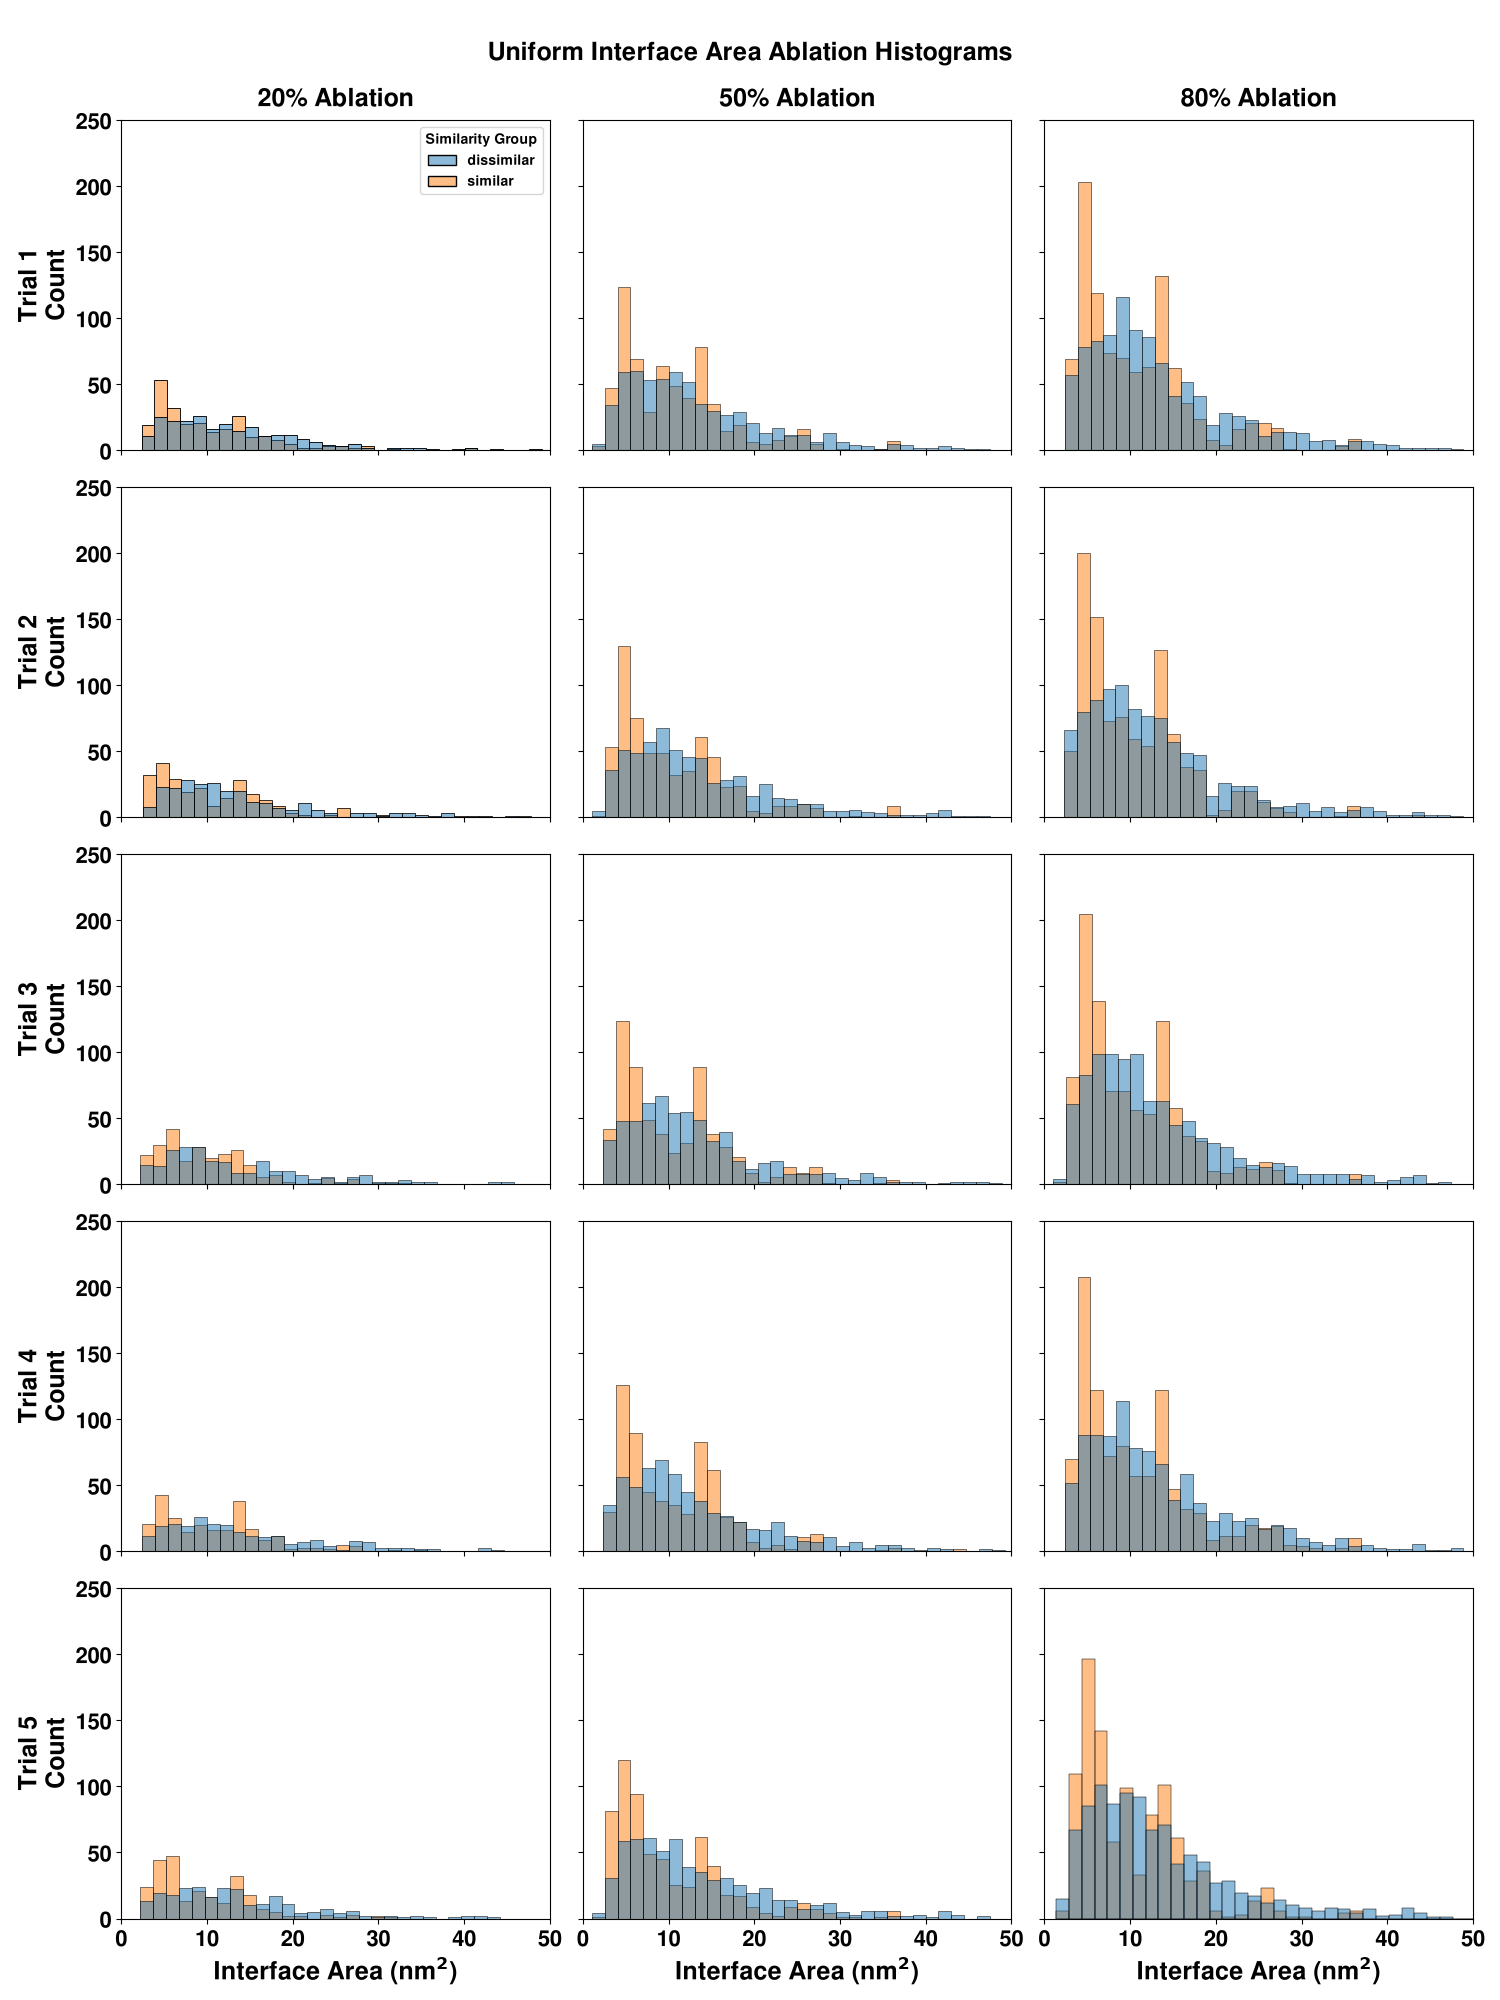

In [9]:
ablation_types = ['targeted', 'uniform']
ablation_levels = ['20', '50', '80']
num_trials = 5

for ab_type in ablation_types:
    # Create a 5x3 figure for the current ablation type
    if ab_type == 'uniform':
        fig, axes = plt.subplots(nrows=num_trials, ncols=len(ablation_levels), 
                                 figsize=(15, 20), sharex=True, sharey=True)
        fig.suptitle(f'{ab_type.capitalize()} Interface Area Ablation Histograms', fontsize=18, y=0.98, fontweight='bold')
    else:
        fig, axes = plt.subplots(nrows=num_trials, ncols=len(ablation_levels), 
                                 figsize=(15, 20), sharex=True, sharey=True)
        fig.suptitle(f'{ab_type.capitalize()} Interface Area Ablation Histograms', fontsize=18, y=0.98, fontweight='bold')

    max_bar_height = 0 #this will track of the max bar height across all subplots, and at the end we'll iterate back over axes and set
    max_interface_area = 0 #this serves a similar purpose, except for the x-axis
    for col, level in enumerate(ablation_levels):
        for trial in range(num_trials):
            ax = axes[trial, col]
            
            # Dynamically format filenames
            prefix = f'similarities/aminobert-esm2-interfacearea{level}-{ab_type}-trial_{trial}'
            val_sims = load_similarity_data(f'{prefix}-val-similarities.dat')
            train_sims = load_similarity_data(f'{prefix}-train-similarities.dat')
            holdout_sims = load_similarity_data(f'{prefix}-holdout-similarities.dat')
            # Remove holdouts from the validation set
            val_sims = val_sims[~val_sims['complex_path'].isin(holdout_sims['complex_path'])]
            val_info = pd.merge(val_sims, complex_info, on='complex_path', how='inner').sort_values(by='CKA', ascending=True)
            # Label top 20% cka, bottom 20% cka, and rest
            val_info['Similarity Group'] = pd.qcut(val_info['CKA'], q=[0, 0.2, 0.8, 1.0], labels=['dissimilar', 'neutral', 'similar'])
            # Filter out 'neutral'
            val_info = val_info[val_info['Similarity Group'] != 'neutral']
            val_info['Similarity Group'] = val_info['Similarity Group'].cat.remove_unused_categories()


            # Only show the legend on the top-left subplot to avoid clutter
            show_legend = (trial == 0 and col == 0)

            # binwidth is set to a constant value

            p = sns.histplot(data=val_info, x='interface_area', hue='Similarity Group', 
                                fill=True, ax=ax, legend=show_legend, binwidth=1.5)

            #calculate max height, update the global max_bar_height if necessary
            max_height = max(bar.get_height() for bar in p.patches)
            if max_height > max_bar_height:
                max_bar_height = max_height

            #calculate max interface area, update the global max_interface_area if necessary
            max_area = val_info['interface_area'].max()
            if max_area > max_interface_area:
                max_interface_area = max_area
            

            # sns.kdeplot(data=complex_info, x = 'interface_area', fill=True, ax=ax, color='green')
            
            # Format titles and axis labels for the grid
            if col == 0:
                ax.tick_params(axis='y', which='major', labelsize=16)
            if trial == 4:
                ax.tick_params(axis='x', which='major', labelsize=16)


            #ylim should be the same across subplots, set it explicitly
            ax.set_ylim(0, max_bar_height)
                
            if trial == 0:
                ax.set_title(f'{level}% Ablation', fontsize=18, pad=10, fontweight='bold')
            
            if col == 0:
                ax.set_ylabel(f'Trial {trial+1}\nCount', fontsize=18, fontweight='bold')
            else:
                ax.set_ylabel('')
                
            if trial == num_trials - 1:
                ax.set_xlabel('Interface Area (nm$^2$)', fontsize=18, fontweight='bold')
            else:
                ax.set_xlabel('')

    max_bar_height = math.ceil(max_bar_height / 50) * 50
    max_interface_area = math.ceil(max_interface_area / 500) * 500

    for ax in axes.flatten():
        ax.set_ylim(0, max_bar_height)
        ax.set_xlim(0, 50)
    plt.tight_layout()
    # Adjust layout to make room for the suptitle
    plt.subplots_adjust(top=0.94) 
    plt.show()

# Comparing across ablations

Is there any trend of what characterizes dissimilar/similar that either holds or differs across ablation conditions? For instance, the 

# What do the rescount ablations look like?

I think its cool that the model looks like it does poorly precisely on interface areas it doesn't have data on, even though that's not really what it's predicting in the first place. 

But maybe that's not very exciting, or indicative of interface area being in any way special. So what's it like for the rescount ablations?

ANSWER: About the same. Probably because rescount and interface area are correlated. Now it's a question of "if I did this for some dummy variable, would it show this behavior?" But that would require a lot of extra work, so I won't pursure it.

<Axes: xlabel='interface_res_count', ylabel='Density'>

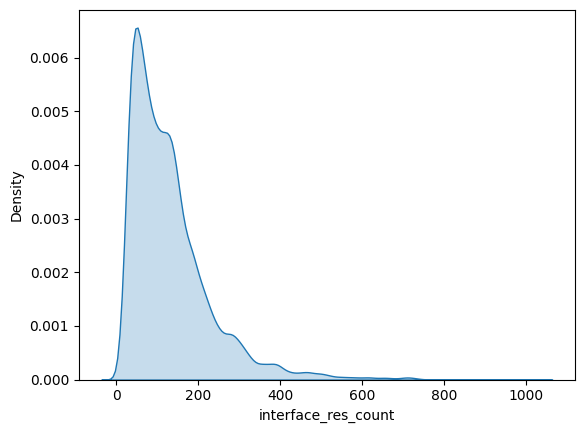

In [ ]:
sns.kdeplot(data=complex_info, x='interface_res_count', fill=True)

In [ ]:
data = complex_info['interface_res_count'].values

peak_x, peak_y = find_kde_peaks(data)

print("Peak x-values:", peak_x)
print("Peak y-values:", peak_y)


Peak x-values: [  50.42242242  380.74074074  463.06306306  612.27227227  653.43343343
  711.05905906  803.67167167  836.6006006   869.52952953  929.21321321
 1009.47747748]
Peak y-values: [6.57734448e-03 2.95162889e-04 1.39697960e-04 4.09812918e-05
 3.31104999e-05 3.93587484e-05 1.84035261e-06 1.74730219e-06
 9.04912737e-07 1.68925204e-06 6.40081890e-06]


<Axes: xlabel='interface_res_count', ylabel='interface_area'>

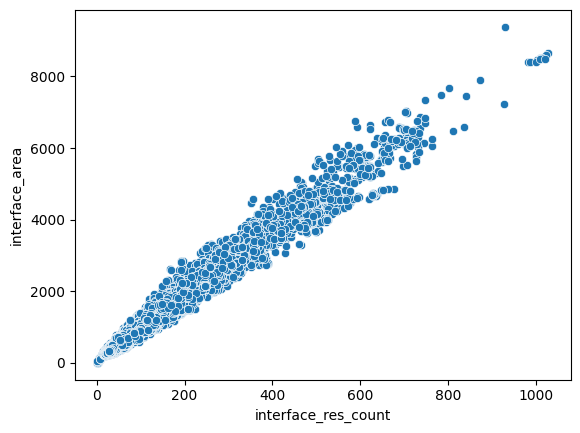

In [ ]:
sns.scatterplot(data=complex_info, x='interface_res_count', y='interface_area')

In [ ]:
PERCENT_ABLATE=20
TRIAL=1
ABLATE_TYPE='targeted'

# load in one specific trial
val_sims = load_similarity_data(f'similarities/aminobert-esm2-rescount{PERCENT_ABLATE}-{ABLATE_TYPE}-trial_{TRIAL}-val-similarities.dat')
train_sims = load_similarity_data(f'similarities/aminobert-esm2-rescount{PERCENT_ABLATE}-{ABLATE_TYPE}-trial_{TRIAL}-train-similarities.dat')
holdout_sims = load_similarity_data(f'similarities/aminobert-esm2-rescount{PERCENT_ABLATE}-{ABLATE_TYPE}-trial_{TRIAL}-holdout-similarities.dat')

#remove holdouts from the validation set
val_sims = val_sims[~val_sims['complex_path'].isin(holdout_sims['complex_path'])]
display(val_sims)

,complex_path,CKA
0,qd/1qdo.pdb1_3.dill,0.591933
1,qw/4qwj.pdb1_44.dill,0.947320
5,qw/4qw1.pdb1_19.dill,0.934339
6,g3/2g3o.pdb1_0.dill,0.611263
7,sq/1sql.pdb1_7.dill,0.598324
...,...,...
2918,ud/3udw.pdb1_2.dill,0.612852
2919,bh/1bhn.pdb1_8.dill,0.734977
2922,ul/1ul1.pdb1_0.dill,0.384489
2924,im/4imd.pdb1_3.dill,0.741557


In [ ]:
val_info = pd.merge(val_sims, complex_info, on='complex_path', how='inner').sort_values(by='CKA', ascending=True)
#label top 20%cka, bottom 20%cka, and rest. top is "similar", bottom is "dissimilar", rest is "neutral"
val_info['Similarity Group'] = pd.qcut(val_info['CKA'], q=[0, 0.2, 0.8, 1.0], labels=['dissimilar', 'neutral', 'similar'])
val_info

,complex_path,CKA,seq1_len,seq2_len,interface_res_count,interface_area,Similarity Group
831,ud/3udg.pdb2_0.dill,0.001181,214,214,94,1073.161434,dissimilar
770,bk/2bkk.pdb1_0.dill,0.001860,247,155,85,884.083694,dissimilar
28,lm/4lmf.pdb6_0.dill,0.002095,276,276,87,919.345841,dissimilar
919,xj/1xjb.pdb1_0.dill,0.002340,325,322,109,1163.500325,dissimilar
1026,bo/3bol.pdb1_0.dill,0.002816,557,549,115,1090.063485,dissimilar
...,...,...,...,...,...,...,...
1,qw/4qwj.pdb1_44.dill,0.947320,212,195,85,773.520625,similar
276,qw/4qw0.pdb1_45.dill,0.948197,212,195,76,758.846541,similar
986,v5/3v5i.pdb2_3.dill,0.958045,184,184,100,820.033889,similar
47,v5/3v5i.pdb1_26.dill,0.958045,184,184,99,809.427785,similar


<Axes: xlabel='interface_res_count', ylabel='Density'>

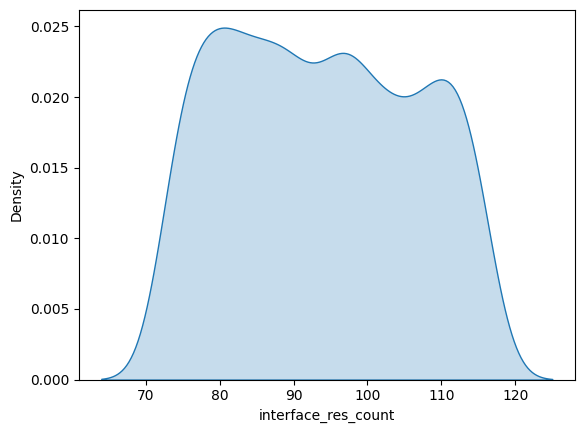

In [ ]:
# See the dist of the complete set
sns.kdeplot(data=val_info, x='interface_res_count', fill=True)

/tmp/ipykernel_3104736/3139270751.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val_info['Similarity Group'] = val_info['Similarity Group'].cat.remove_unused_categories()


<Axes: xlabel='interface_res_count', ylabel='Density'>

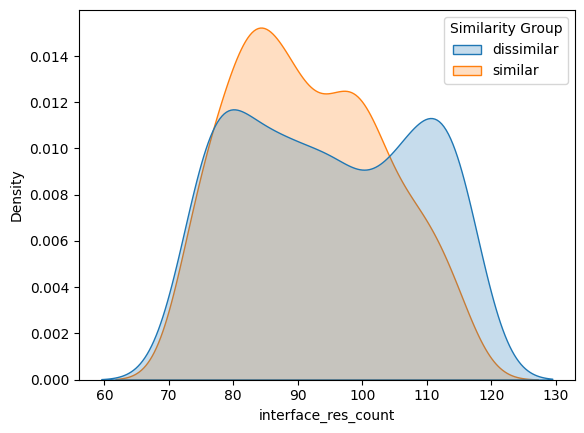

In [ ]:
# REMOVE THE UNUSED CATEGORY
val_info = val_info[val_info['Similarity Group'] != 'neutral']
val_info['Similarity Group'] = val_info['Similarity Group'].cat.remove_unused_categories()
sns.kdeplot(data=val_info, x='interface_res_count', hue='Similarity Group', fill=True)

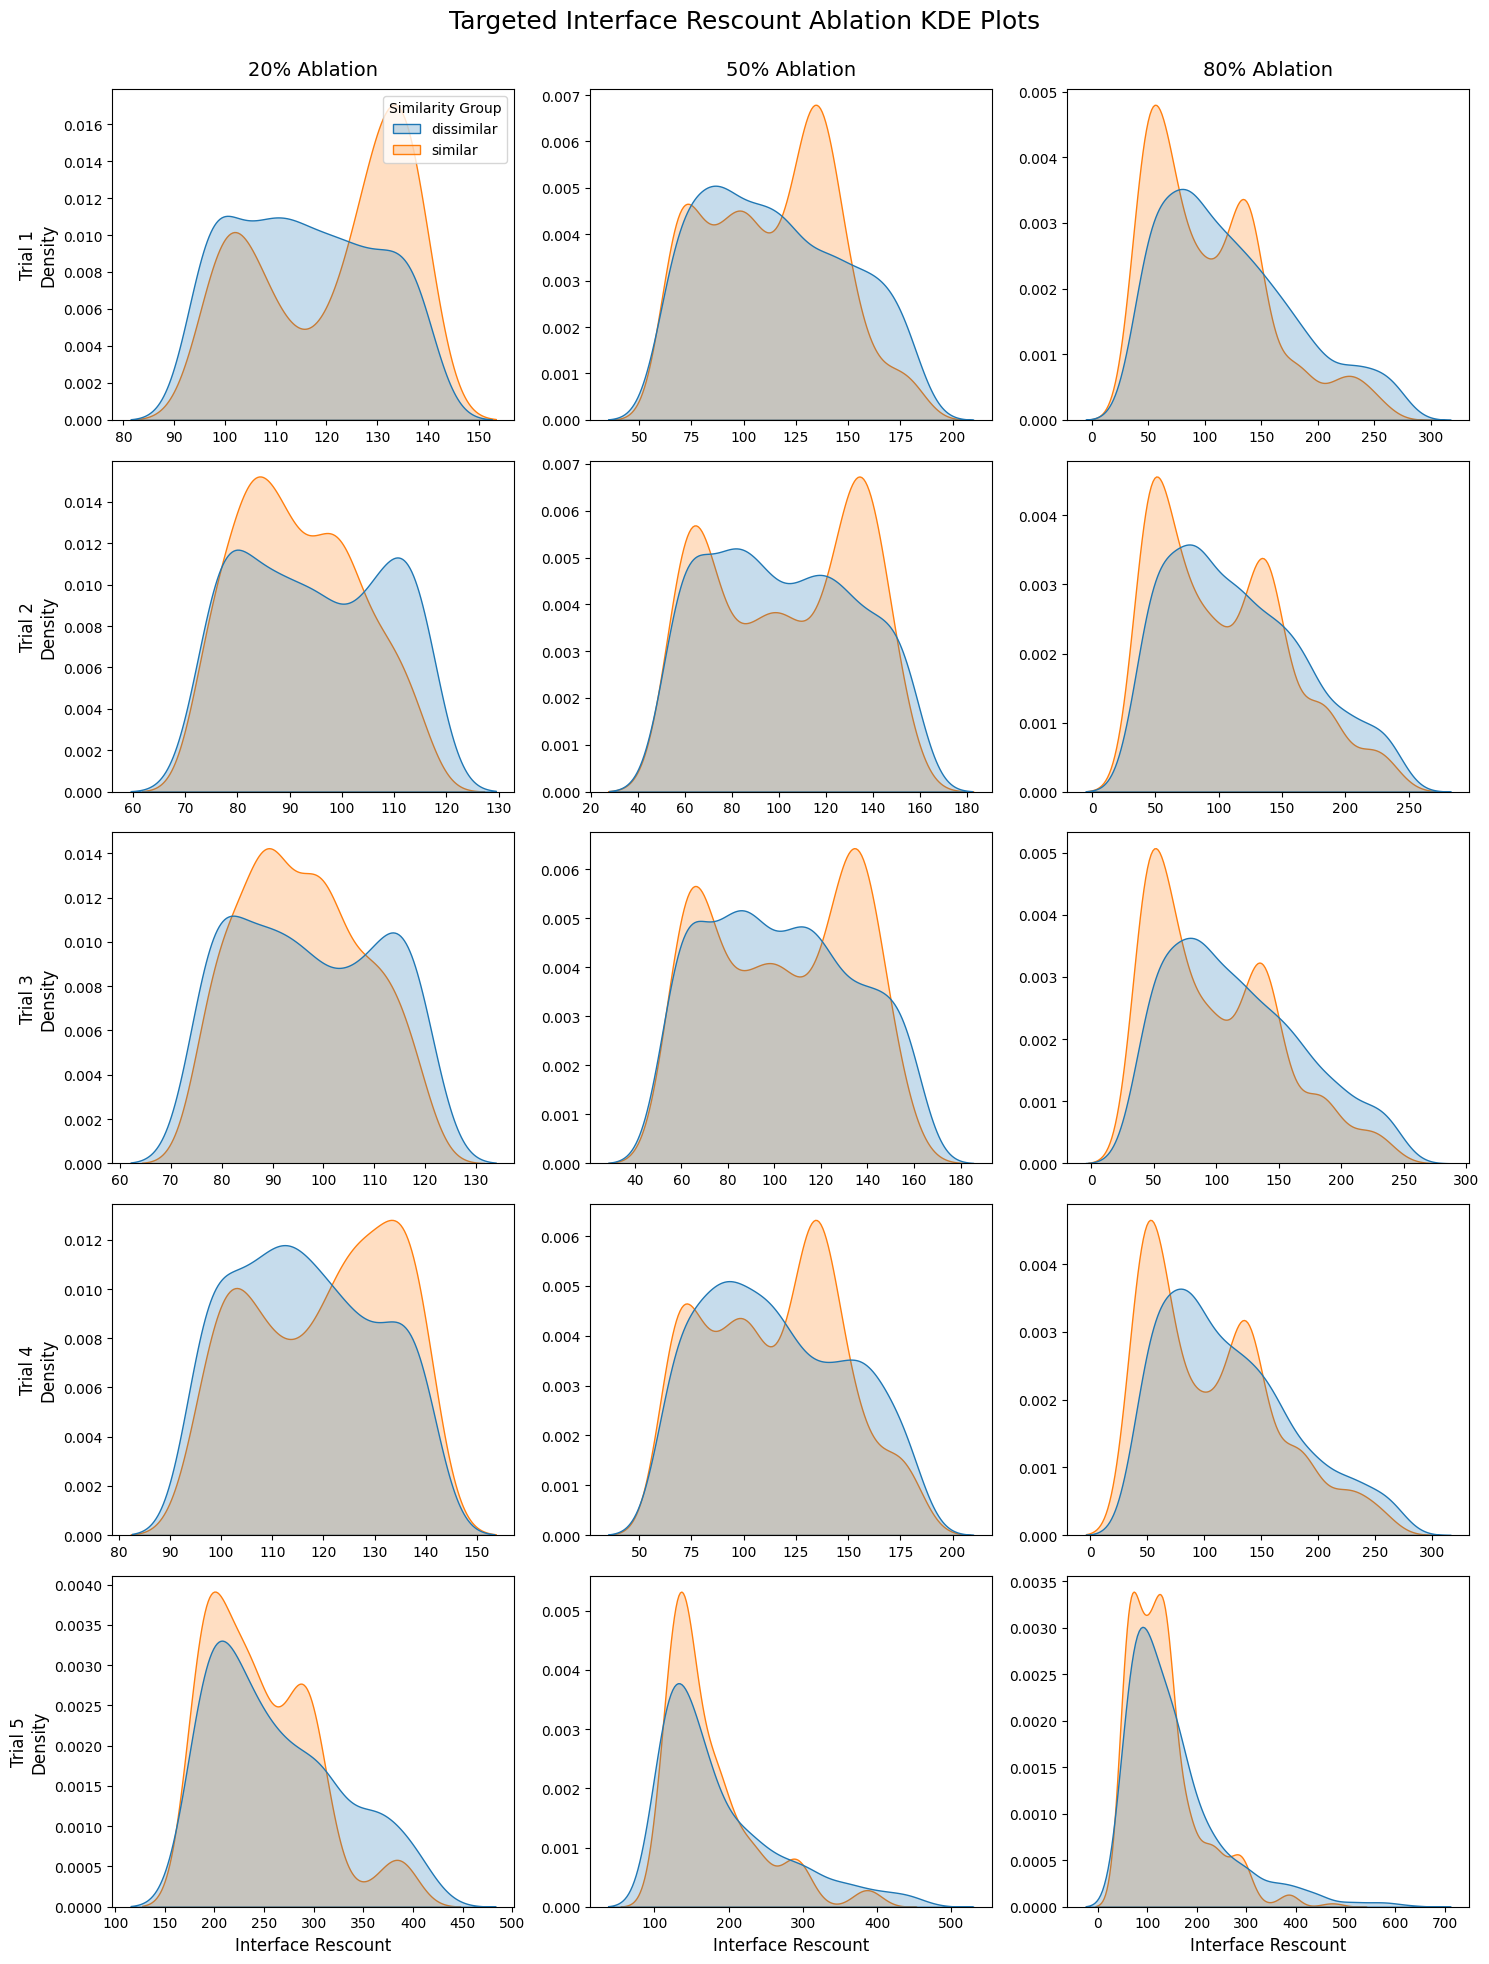

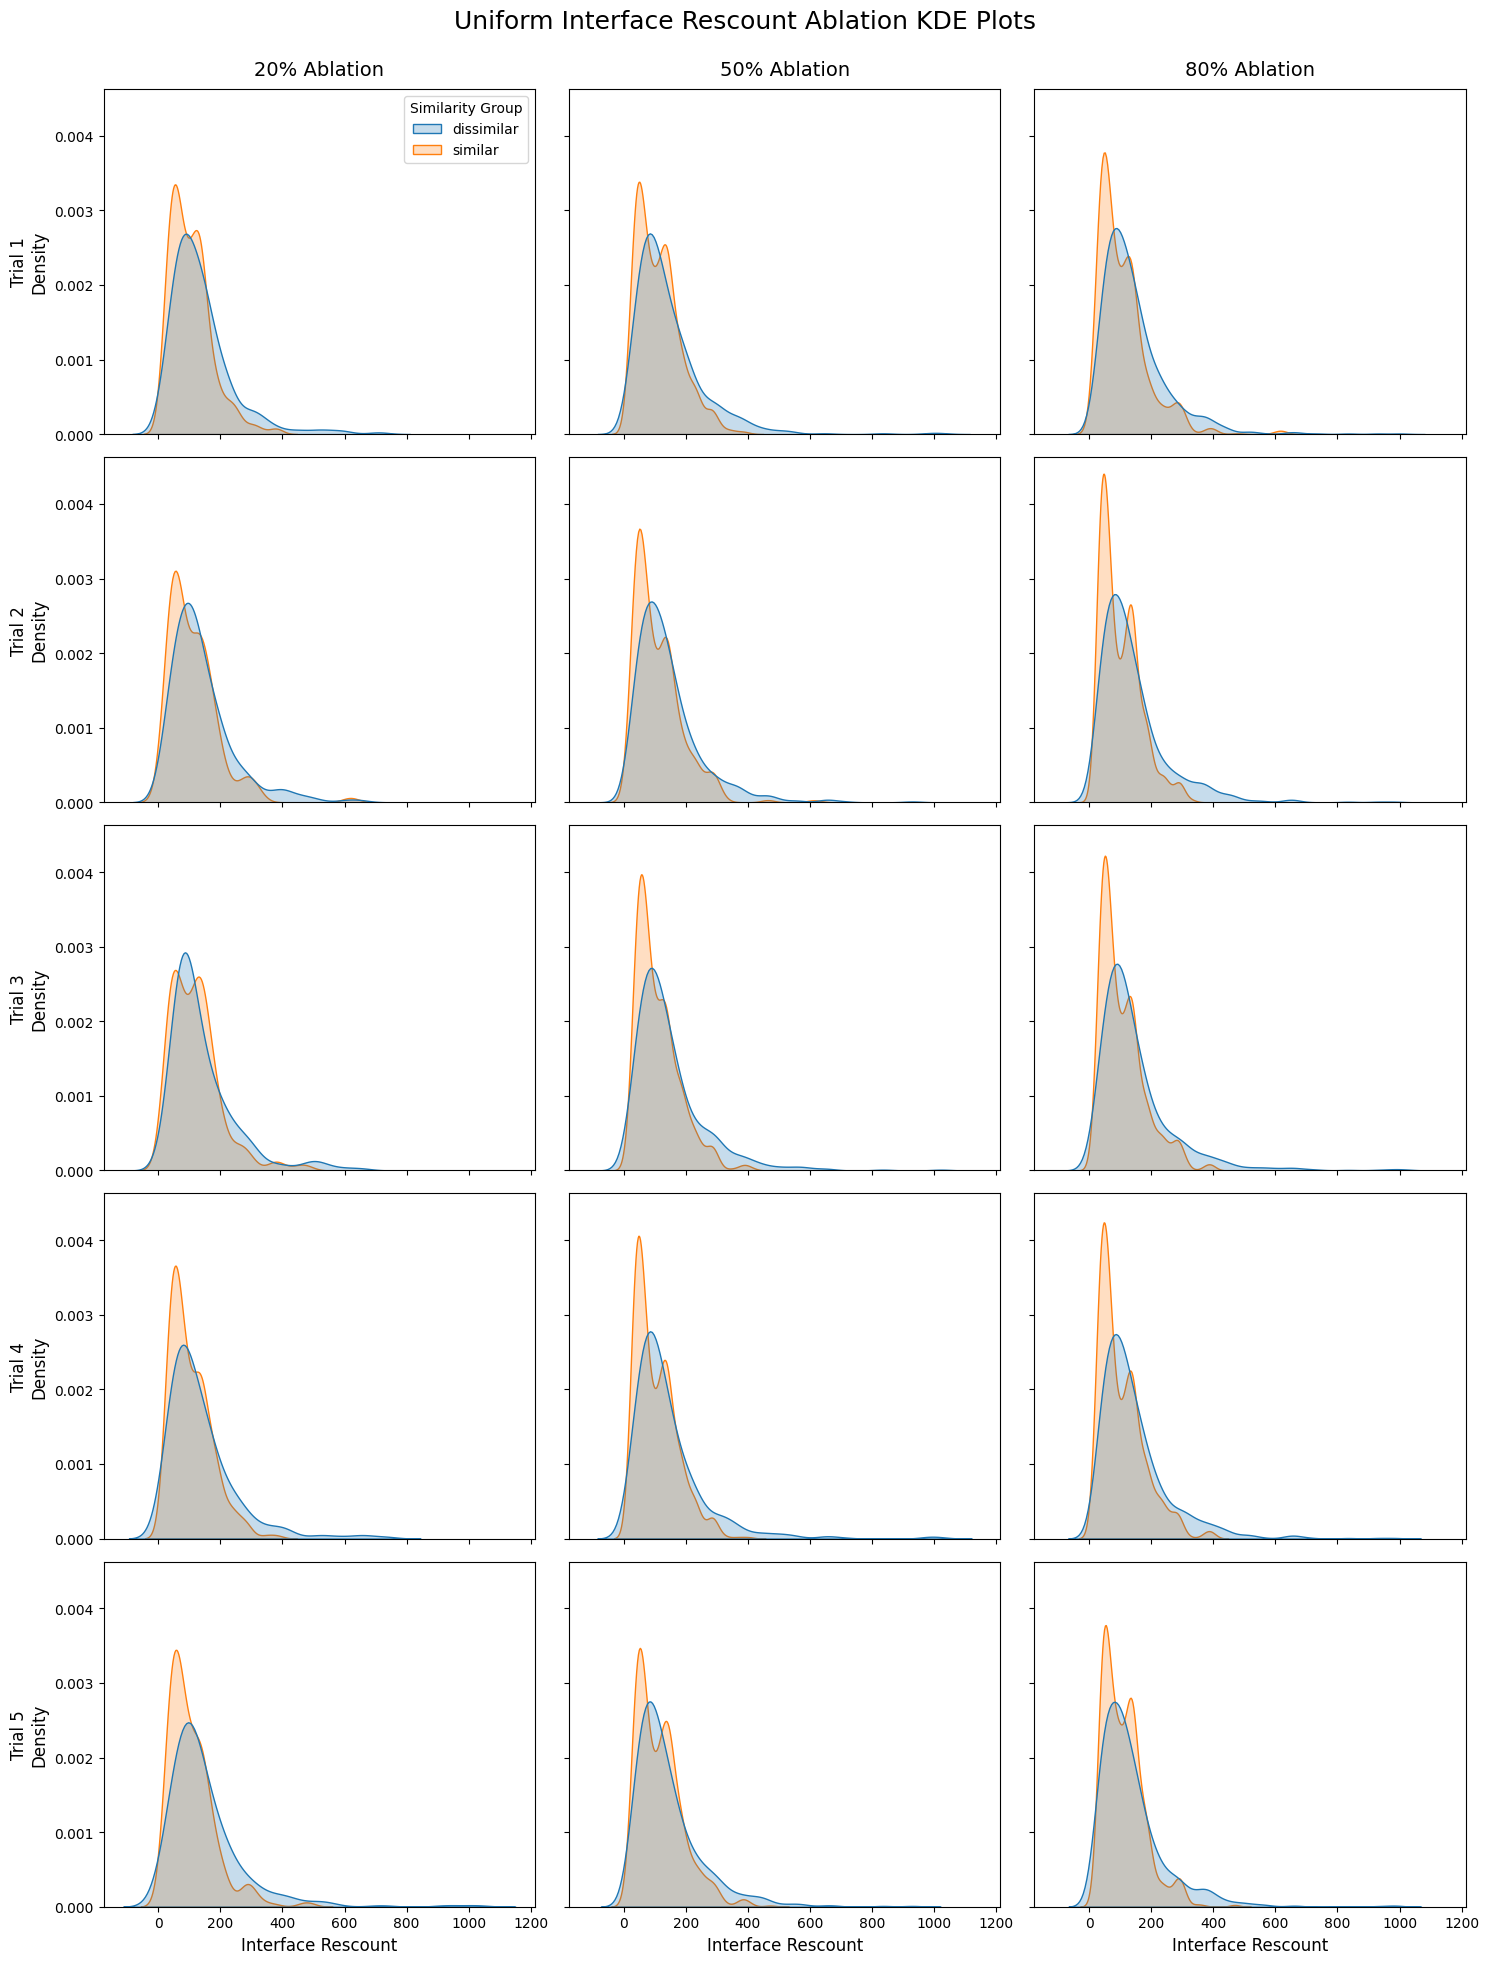

In [ ]:
ablation_types = ['targeted', 'uniform']
ablation_levels = ['20', '50', '80']
num_trials = 5

for ab_type in ablation_types:
    # Create a 5x3 figure for the current ablation type
    if ab_type == 'uniform':
        fig, axes = plt.subplots(nrows=num_trials, ncols=len(ablation_levels), 
                                 figsize=(15, 20), sharex=True, sharey=True)
        fig.suptitle(f'{ab_type.capitalize()} Interface Rescount Ablation KDE Plots', fontsize=18, y=0.98)
    else:
        fig, axes = plt.subplots(nrows=num_trials, ncols=len(ablation_levels), 
                                 figsize=(15, 20), sharex=False, sharey=False)
        fig.suptitle(f'{ab_type.capitalize()} Interface Rescount Ablation KDE Plots', fontsize=18, y=0.98)
    for col, level in enumerate(ablation_levels):
        for trial in range(num_trials):
            ax = axes[trial, col]
            
            # Dynamically format filenames
            prefix = f'similarities/aminobert-esm2-rescount{level}-{ab_type}-trial_{trial}'
            val_sims = load_similarity_data(f'{prefix}-val-similarities.dat')
            train_sims = load_similarity_data(f'{prefix}-train-similarities.dat')
            holdout_sims = load_similarity_data(f'{prefix}-holdout-similarities.dat')

            # Remove holdouts from the validation set
            val_sims = val_sims[~val_sims['complex_path'].isin(holdout_sims['complex_path'])]

            val_info = pd.merge(val_sims, complex_info, on='complex_path', how='inner').sort_values(by='CKA', ascending=True)
            
            # Label top 20% cka, bottom 20% cka, and rest
            val_info['Similarity Group'] = pd.qcut(val_info['CKA'], q=[0, 0.2, 0.8, 1.0], labels=['dissimilar', 'neutral', 'similar'])
            
            # Filter out 'neutral'
            val_info = val_info[val_info['Similarity Group'] != 'neutral']
            val_info['Similarity Group'] = val_info['Similarity Group'].cat.remove_unused_categories()
            
            # Only show the legend on the top-left subplot to avoid clutter
            show_legend = (trial == 0 and col == 0)
            
            sns.kdeplot(data=val_info, x='interface_res_count', hue='Similarity Group', 
                        fill=True, ax=ax, legend=show_legend)

            # sns.kdeplot(data=complex_info, x = 'interface_res_count', fill=True, ax=ax, color='green')
            
            # Format titles and axis labels for the grid
            if trial == 0:
                ax.set_title(f'{level}% Ablation', fontsize=14, pad=10)
            
            if col == 0:
                ax.set_ylabel(f'Trial {trial+1}\nDensity', fontsize=12)
            else:
                ax.set_ylabel('')
                
            if trial == num_trials - 1:
                ax.set_xlabel('Interface Rescount', fontsize=12)
            else:
                ax.set_xlabel('')

    plt.tight_layout()
    # Adjust layout to make room for the suptitle
    plt.subplots_adjust(top=0.94) 
    plt.show()